# Segmentação de pluma de fumaça com SAM 2
**Modelagem Computacional — atividade individual**

Objetivo: comparar três configurações de prompts (caixa, caixa + pontos positivos, caixa + pontos positivos e negativos), avaliando visualmente os erros de segmentação.

**Instrução:** execute as células em ordem. Escolha uma fotografia com pluma visível e ajuste as coordenadas dos prompts na célula de configuração. Registre observações próprias após visualizar os resultados.


In [1]:
# Instalar SAM 2 (execute uma única vez)
!git clone -q https://github.com/facebookresearch/sam2.git
%cd /content/sam2
!pip -q install -e .
!pip -q install opencv-python matplotlib pillow
!mkdir -p checkpoints
!wget -q -nc -P checkpoints/ https://dl.fbaipublicfiles.com/segment_anything_2/072824/sam2_hiera_small.pt


/content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.0/117.0 kB 9.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 13.4 MB/s eta 0:00:00
  Building editable for SAM-2 (pyproject.toml) ... done


Saving imagem_2026-10-19_221017594.png to imagem_2026-10-19_221017594.png
Imagem: 1200 x 675 pixels


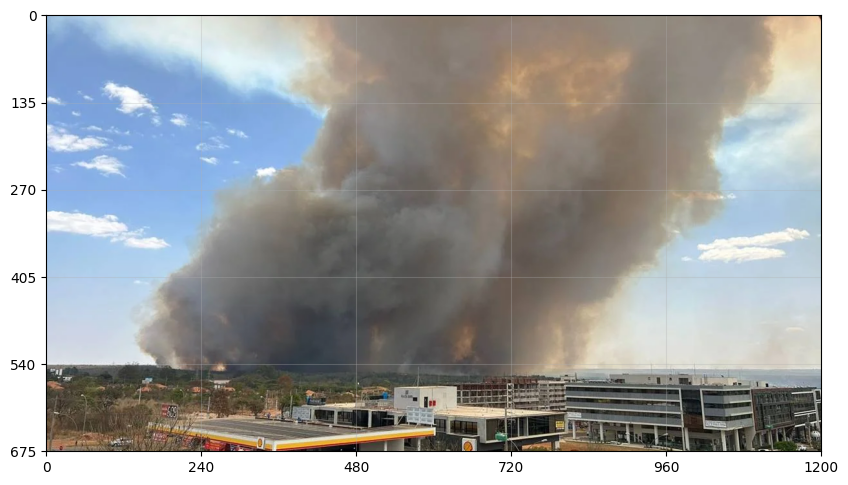

In [2]:
import torch, numpy as np, matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
from contextlib import nullcontext
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

uploaded = files.upload()  # Escolha sua imagem de fumaça
image_path = next(iter(uploaded))
image_np = np.array(Image.open(image_path).convert('RGB'))
h, w = image_np.shape[:2]
print(f'Imagem: {w} x {h} pixels')
plt.figure(figsize=(10,6)); plt.imshow(image_np); plt.xlim(0,w); plt.ylim(h,0)
plt.xticks(np.linspace(0,w,6,dtype=int)); plt.yticks(np.linspace(0,h,6,dtype=int)); plt.grid(alpha=.3); plt.show()


## Configuração manual dos prompts
Observe a imagem com a grade acima. **Altere os valores abaixo** para que a caixa englobe a pluma e os pontos positivos fiquem sobre a fumaça. Coloque os pontos negativos em regiões que não são fumaça (céu, nuvens, edifícios). Coordenadas são `(x, y)`, com origem no canto superior esquerdo.


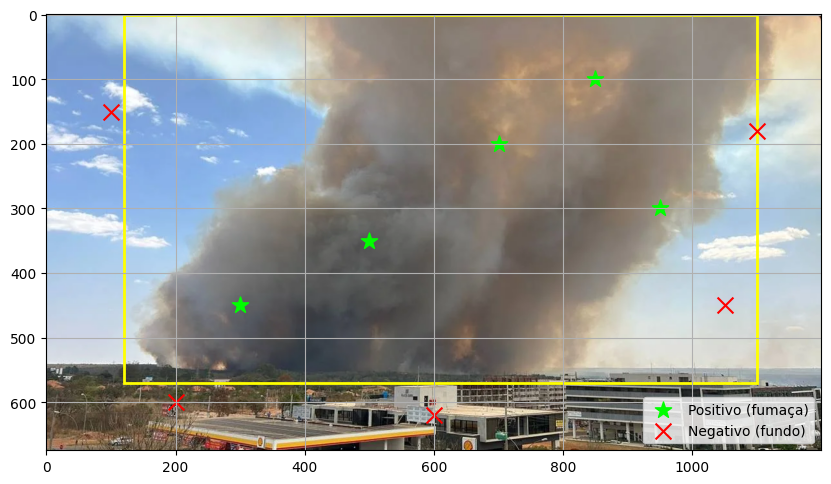

In [3]:
# Caixa delimitadora da fumaça
caixa = np.array([120, 0, 1100, 570], dtype=np.float32)

# Pontos positivos: regiões com fumaça
pontos_positivos = np.array([
    [300, 450],
    [500, 350],
    [700, 200],
    [850, 100],
    [950, 300]
], dtype=np.float32)

# Pontos negativos: céu e edifícios
pontos_negativos = np.array([
    [100, 150],
    [1100, 180],
    [1050, 450],
    [600, 620],
    [200, 600]
], dtype=np.float32)

assert 0 <= caixa[0] < caixa[2] <= w and 0 <= caixa[1] < caixa[3] <= h

for p in np.vstack([pontos_positivos, pontos_negativos]):
    assert 0 <= p[0] < w and 0 <= p[1] < h

from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(image_np)

ax.add_patch(Rectangle(
    (caixa[0], caixa[1]),
    caixa[2] - caixa[0],
    caixa[3] - caixa[1],
    fill=False,
    edgecolor='yellow',
    linewidth=2
))

ax.scatter(pontos_positivos[:, 0], pontos_positivos[:, 1],
           c='lime', marker='*', s=150, label='Positivo (fumaça)')

ax.scatter(pontos_negativos[:, 0], pontos_negativos[:, 1],
           c='red', marker='x', s=130, label='Negativo (fundo)')

ax.legend()
ax.grid()
plt.show()


In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo:', device)
model = build_sam2('configs/sam2.1/sam2.1_hiera_s.yaml' if False else 'sam2_hiera_s.yaml',
                   'checkpoints/sam2_hiera_small.pt', device=device)
predictor = SAM2ImagePredictor(model)
predictor.set_image(image_np)

def segmentar(box, positivos=None, negativos=None):
    pts, labels = [], []
    if positivos is not None:
        pts.extend(positivos.tolist()); labels.extend([1]*len(positivos))
    if negativos is not None:
        pts.extend(negativos.tolist()); labels.extend([0]*len(negativos))
    contexto = torch.autocast('cuda', dtype=torch.bfloat16) if device == 'cuda' else nullcontext()
    with torch.inference_mode(), contexto:
        masks, scores, _ = predictor.predict(
            box=box,
            point_coords=np.array(pts,dtype=np.float32) if pts else None,
            point_labels=np.array(labels,dtype=np.int32) if labels else None,
            multimask_output=True)
    idx = int(np.argmax(scores))
    return masks[idx].astype(bool), float(scores[idx])

resultados = {
    '1 — Caixa': segmentar(caixa),
    '2 — Caixa + positivos': segmentar(caixa, pontos_positivos),
    '3 — Caixa + positivos + negativos': segmentar(caixa, pontos_positivos, pontos_negativos)
}


Dispositivo: cuda


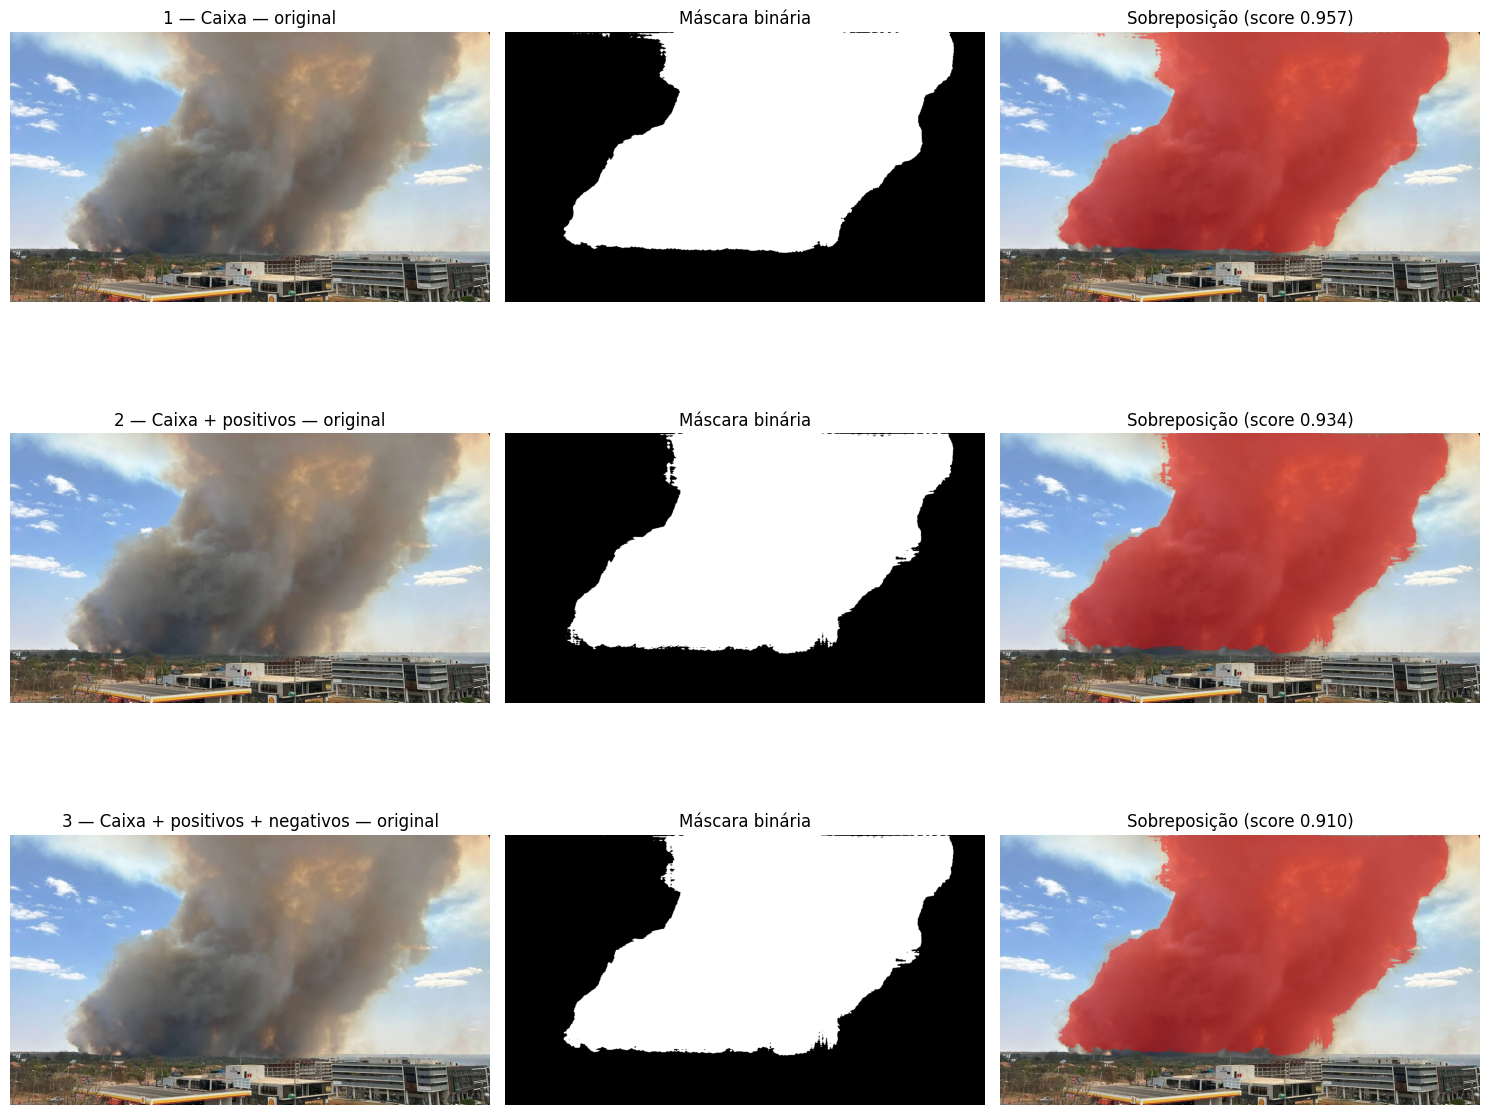

1 — Caixa: 46.61% da imagem selecionada | score do SAM = 0.957
2 — Caixa + positivos: 45.19% da imagem selecionada | score do SAM = 0.934
3 — Caixa + positivos + negativos: 45.66% da imagem selecionada | score do SAM = 0.910
Atenção: score e área selecionada NÃO comprovam que a segmentação está correta.


In [5]:
# Comparação: original, máscara binária e sobreposição para cada teste
fig, axs = plt.subplots(3, 3, figsize=(15, 13))
for i, (nome, (mask, score)) in enumerate(resultados.items()):
    axs[i,0].imshow(image_np); axs[i,0].set_title(f'{nome} — original')
    axs[i,1].imshow(mask, cmap='gray', vmin=0, vmax=1); axs[i,1].set_title('Máscara binária')
    axs[i,2].imshow(image_np)
    rgba = np.zeros((h,w,4), dtype=float); rgba[...,0]=1; rgba[...,3]=mask.astype(float)*.45
    axs[i,2].imshow(rgba); axs[i,2].set_title(f'Sobreposição (score {score:.3f})')
    for ax in axs[i]: ax.axis('off')
plt.tight_layout(); plt.savefig('/content/comparacao_sam.png', dpi=150, bbox_inches='tight'); plt.show()
for nome,(mask,score) in resultados.items():
    print(f'{nome}: {mask.mean()*100:.2f}% da imagem selecionada | score do SAM = {score:.3f}')
print('Atenção: score e área selecionada NÃO comprovam que a segmentação está correta.')


## Análise crítica do projeto

**Teste 1 — somente caixa:** A utilização apenas da caixa apresentou um resultado satisfatório, identificando grande parte da fumaça e excluindo a maior parte do cenário ao redor. O score obtido foi de 0,957.

**Teste 2 — caixa e pontos positivos:** A adição de pontos positivos manteve a identificação da pluma, mas provocou pequenas alterações nas bordas. O score foi de 0,934, sem uma melhoria visual significativa em relação ao primeiro teste.

**Teste 3 — caixa, pontos positivos e negativos:** A inclusão de pontos negativos ajudou a orientar o modelo sobre as regiões que não pertencem à fumaça. Entretanto, o resultado permaneceu semelhante aos anteriores, apresentando score de 0,910.

**Dificuldades da imagem:** A principal dificuldade foi a semelhança entre a fumaça e as nuvens, principalmente nas regiões superiores da imagem. A iluminação também interferiu na aparência da pluma, criando áreas mais claras e outras mais escuras. Além disso, as bordas difusas dificultaram a identificação exata dos limites da fumaça.

**Conclusão:** Os três testes apresentaram resultados satisfatórios. A configuração utilizando apenas a caixa delimitadora demonstrou ser suficiente para identificar a maior parte da pluma nesta imagem. Os pontos adicionais modificaram os contornos, mas não trouxeram melhorias visuais expressivas. Isso mostra que a eficácia dos prompts depende das características da imagem analisada
